# Loading data

In [177]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import scipy

datapath = "weekly/week3/collected_data_unlimited.csv"

df = pd.read_csv(datapath)
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

df.head()

MAX_REPLICA_COUNT = df['Count'].max() + 1

replica_graphs = []

def get_replica_row(replica_num, group):
    if len(group) >= replica_num:
        return group.iloc[replica_num-1:replica_num]

grouped = df.groupby('Timestamp')

node_stats = grouped.apply(lambda x: x.iloc[0]).reset_index(drop=True)
pod_stats = grouped.apply(lambda x: x.iloc[1]).reset_index(drop=True)

node_stats['Memory'] = node_stats['Memory'].str.split("Mi").apply(lambda x: int(x[0]))

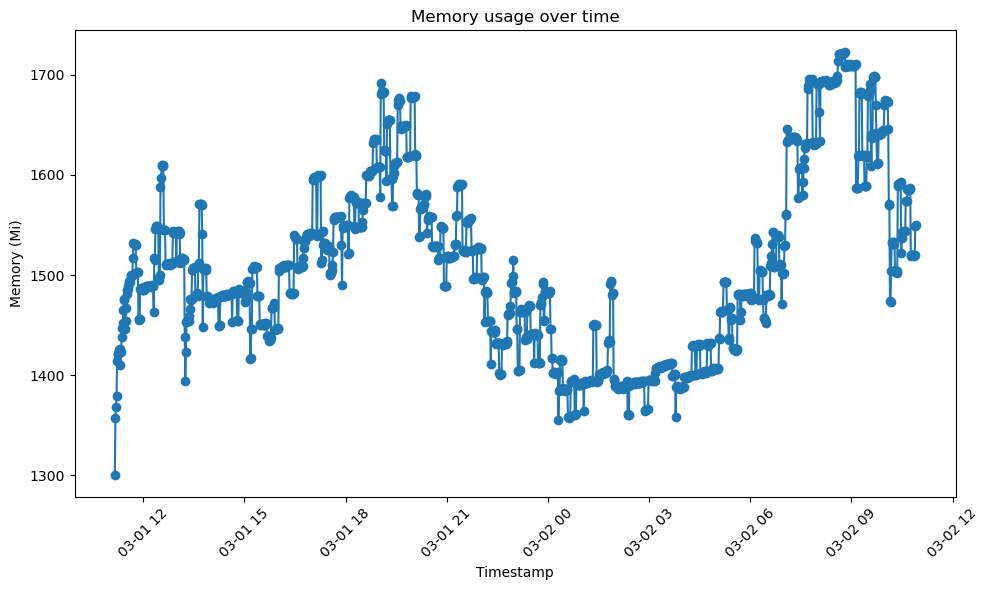

In [178]:
plt.figure(figsize=(10, 6))
plt.plot(node_stats.sort_values(by='Timestamp')['Timestamp'], node_stats['Memory'], marker='o', linestyle='-')
plt.title('Memory usage over time')
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')
plt.xticks(rotation=45)  
plt.tight_layout()  
plt.show()

In [179]:
#split data
time_to_split = node_stats['Timestamp'][700]
print("Train time split:", time_to_split)

def get_timestamp(date):
    return date.timestamp()

node_stats['Time'] = node_stats['Timestamp'].map(get_timestamp)
X = node_stats['Time'].to_numpy()
Y = node_stats['Memory'].to_numpy()

train_df = node_stats[node_stats['Timestamp'] <= time_to_split].copy()
train_df['Time'] = train_df['Timestamp'].map(get_timestamp)
X_train = train_df['Time'].to_numpy()
Y_train = train_df['Memory'].to_numpy()

#plt.plot(X_train, Y_train)

Train time split: 2024-03-01 22:52:30


# Model

This predicts the required amount of resource required for a Kubernetes cluster. It uses a modifed weiner process with drift to make a probabilitic prediction. This assumes homogenuity, all collected data is of the same type. It also assumes evenly spaced inputs, the code must be modified before handling irregularly spaced inputs.

In [201]:
# Non-weighted
def moving_average(a, n=5):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    ns = np.full(ret.shape, n)
    ns[:n-1] = range(1, n)
    return ret / ns

class Resource_Predictor():
    def __init__(self, window_size=5, max_history=50):
        self.fitted = False
        self.window_size=60
        self.max_history=100
        
    def fit(self, X, Y):
        X = X[-self.max_history:]
        Y = Y[-self.max_history:]
        
        assert len(X) >= self.window_size
        
        n = len(X)
        
        #assumes evenly spaced
        self.step = X[1] - X[0]
        self.last = X[-1]
        self.lastY = Y[-1]
        
        rolling_mean = moving_average(Y, self.window_size)
        residual = Y - rolling_mean
        self.noise = np.sqrt(np.sum(residual ** 2) / (n-1))
        
        rolling_diff = np.diff(rolling_mean)
        self.sigma = np.sqrt(np.sum(rolling_diff ** 2) / (n-1))
        
        self.drift = (rolling_mean[-1] - rolling_mean[-self.window_size]) / self.window_size
        
        self.fitted = True
        
    def fit_Y(self, Y):
        X = np.arange(len(Y))
        self.fit(X, Y)
        
    def predict_required_resources(self, x):
        if not self.fitted: return 0
        
        mean = self.predict_mean_resources(x)
        delta = self._variance(x, 1.96, .6)
        
        return mean + delta
    
    def predict_mean_resources(self, x):
        if not self.fitted: return 0
        
        x = self._z(x)
        return self.lastY + x * self.drift
    
    def predict_confidence_interval(self, x):
        if not self.fitted: return 0
        
        mean = self.predict_mean_resources(x)
        delta = self._variance(x, 1.96, 0.6)
        
        return (mean - delta, mean + delta)
    
    def _variance(self, x, z_noise=1, z_sigma=0):
        x = self._z(x)
        return z_noise * self.noise + x * z_sigma * self.sigma
    
    def _z(self, x):
        return (x - self.last)/self.step
    
    def predict_many(self, X):
        return list(map(self.predict_required_resources, X))


In [202]:
model = Resource_Predictor()
model.fit(X_train, Y_train)

In [203]:
print(model.sigma)

2.0893676316368683


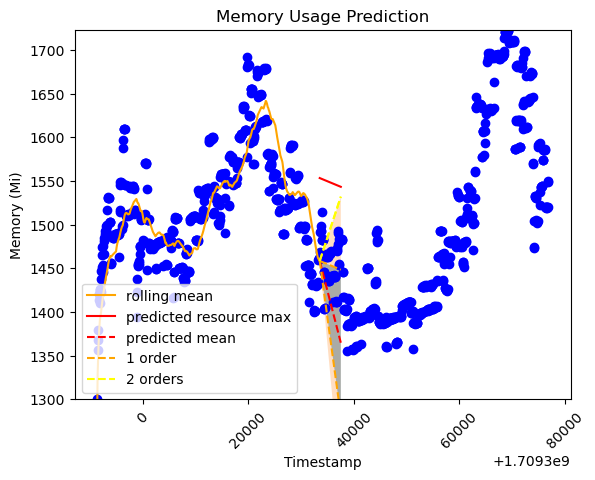

In [207]:
plt.plot(X, Y, 'o', c="b")

plt.plot(X_train, moving_average(Y_train, 60), '-', label='rolling mean', c= 'orange')

xnew = np.arange(max(X_train), max(X_train) + 5000, 1000)
ynew = model.predict_many(xnew)
last_x = max(X_train)
last_y = moving_average(Y_train, 60)[-1]
y_base = last_y + model.drift * (xnew - last_x)/model.step
slope = 0.6 * model.sigma * (xnew - last_x)/model.step

plt.plot(xnew, ynew, '-', c="red", label = "predicted resource max")
plt.plot(xnew, y_base, '--', c="red", label = "predicted mean")
plt.plot(xnew, y_base + slope, '--', c="orange", label = "1 order")
plt.plot(xnew, y_base - slope, '--', c="orange")
plt.fill_between(xnew, y_base - slope, y_base + slope, alpha=0.5)
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow", label = "2 orders")
plt.plot(xnew, y_base + 2 * slope, '--', c="yellow")
plt.fill_between(xnew, y_base - 2 * slope, y_base + 2 * slope, alpha=0.25)


ymin = min(node_stats['Memory'])
ymax = max(node_stats['Memory'])
plt.ylim(ymin, ymax)
plt.xticks(rotation=45)  

plt.title("Memory Usage Prediction")
plt.xlabel('Timestamp')
plt.ylabel('Memory (Mi)')

plt.legend()
plt.show()